# Python Data Structures Overview

A **data structure** is a way to organise values in memory. The choice of data structure decides how fast your program can find, add and remove values.

**After this lesson you can:**

1. Use the basic types: `int`, `float`, `bool`, `str`, `None`.
2. Use the four built-in collections: `list`, `tuple`, `dict`, `set`.
3. Explain mutability and why it matters.
4. Select the correct collection for a task, based on measured speed.

## 1. Basic Types

| Type | Example | Notes |
| :--- | :--- | :--- |
| `int` | `42`, `-7` | Integers of any size (no overflow) |
| `float` | `3.14`, `1e-3` | 64-bit floating-point numbers |
| `bool` | `True`, `False` | A subclass of `int` (`True == 1`) |
| `str` | `"hello"` | Unicode text, immutable |
| `NoneType` | `None` | "No value" |

`type()` shows the type of a value. `isinstance()` checks a type.

In [1]:
values = [42, 3.14, True, "hello", None, 2**100]
for v in values:
    print(f"{v!r:<35} type={type(v).__name__}")

print("\nInteger division and remainder:", 17 // 5, 17 % 5)
print("True division:                 ", 17 / 5)
print("Power:                         ", 2 ** 10)
print("0.1 + 0.2 == 0.3 ?             ", 0.1 + 0.2 == 0.3, "(floating-point rounding)")
print("isinstance(True, int)?         ", isinstance(True, int))

42                                  type=int
3.14                                type=float
True                                type=bool
'hello'                             type=str
None                                type=NoneType
1267650600228229401496703205376     type=int

Integer division and remainder: 3 2
True division:                  3.4
Power:                          1024
0.1 + 0.2 == 0.3 ?              False (floating-point rounding)
isinstance(True, int)?          True


## 2. Strings

A string is an **immutable** sequence of characters. Index positions start at 0. Negative indexes count from the end. A **slice** `s[start:stop:step]` returns a new string.

In [2]:
city = "Istanbul"
print(city[0], city[-1], city[1:4], city[::-1])
print(city.upper(), city.lower(), city.replace("bul", "BUL"))
print("Length:", len(city))

name, score = "Ayse", 92.456
print(f"{name} scored {score:.1f} points")       # f-string with format specifier
print("a,b,c".split(","), "-".join(["2025", "06", "01"]))

try:
    city[0] = "i"
except TypeError as err:
    print("Strings are immutable:", err)

I l sta lubnatsI
ISTANBUL istanbul IstanBUL
Length: 8
Ayse scored 92.5 points
['a', 'b', 'c'] 2025-06-01
Strings are immutable: 'str' object does not support item assignment


## 3. The Four Built-in Collections

| Collection | Syntax | Ordered | Mutable | Duplicates | Typical use |
| :--- | :--- | :-: | :-: | :-: | :--- |
| `list` | `[1, 2, 3]` | yes | yes | yes | sequence that changes |
| `tuple` | `(1, 2, 3)` | yes | no | yes | fixed record, dict key |
| `dict` | `{"a": 1}` | yes (insertion) | yes | keys unique | lookup by key |
| `set` | `{1, 2, 3}` | no | yes | no | membership, unique values |

In [3]:
# list: ordered and mutable
temps = [21.5, 23.0, 19.8]
temps.append(25.1)
temps.insert(0, 18.2)
temps.sort()
print("list :", temps, "| max:", max(temps), "| mean:", round(sum(temps) / len(temps), 2))

# tuple: an immutable record; tuple unpacking
point = (41.01, 28.97)
lat, lon = point
print("tuple:", point, "| lat =", lat)

# dict: key -> value
stock = {"apple": 12, "pear": 5}
stock["plum"] = 7
stock["apple"] -= 2
print("dict :", stock, "| pear?", stock.get("pear"), "| kiwi?", stock.get("kiwi", 0))
for fruit, qty in stock.items():
    print(f"        {fruit:<6} {qty}")

# set: unique values and set algebra
a = {"python", "sql", "git"}
b = {"python", "docker", "git"}
print("set  : union", a | b, "| intersection", a & b, "| only in a", a - b)

list : [18.2, 19.8, 21.5, 23.0, 25.1] | max: 25.1 | mean: 21.52
tuple: (41.01, 28.97) | lat = 41.01
dict : {'apple': 10, 'pear': 5, 'plum': 7} | pear? 5 | kiwi? 0
        apple  10
        pear   5
        plum   7
set  : union {'docker', 'python', 'git', 'sql'} | intersection {'git', 'python'} | only in a {'sql'}


## 4. Mutability and References

A variable is a **name that refers to an object**. Assignment (`b = a`) does not copy the object; both names refer to the same object. If the object is mutable (list, dict, set), a change through one name is visible through the other name.

In [4]:
import copy

a = [1, 2, [3, 4]]
b = a                 # same object
c = a.copy()          # new outer list, shared inner list (shallow copy)
d = copy.deepcopy(a)  # fully independent copy

a[0] = 99
a[2].append(5)
print("a:", a)
print("b:", b, " same object as a:", b is a)
print("c:", c, " shallow copy: outer changed? no; inner list shared")
print("d:", d, " deep copy: nothing shared")

def add_item(item, basket=[]):        # the default list is created ONCE
    basket.append(item)
    return basket

print("\nMutable default argument bug:", add_item("x"), add_item("y"))

a: [99, 2, [3, 4, 5]]
b: [99, 2, [3, 4, 5]]  same object as a: True
c: [1, 2, [3, 4, 5]]  shallow copy: outer changed? no; inner list shared
d: [1, 2, [3, 4]]  deep copy: nothing shared

Mutable default argument bug: ['x', 'y'] ['x', 'y']


The last line shows a classic bug: a mutable default argument keeps its content between calls. Use `basket=None` and create the list inside the function.

## 5. Speed: Why the Choice Matters

A membership test `x in collection` must search a **list** item by item. The time grows with the length: $O(n)$. A **set** or **dict** uses a hash table and finds the item in about constant time: $O(1)$. The experiment measures this.

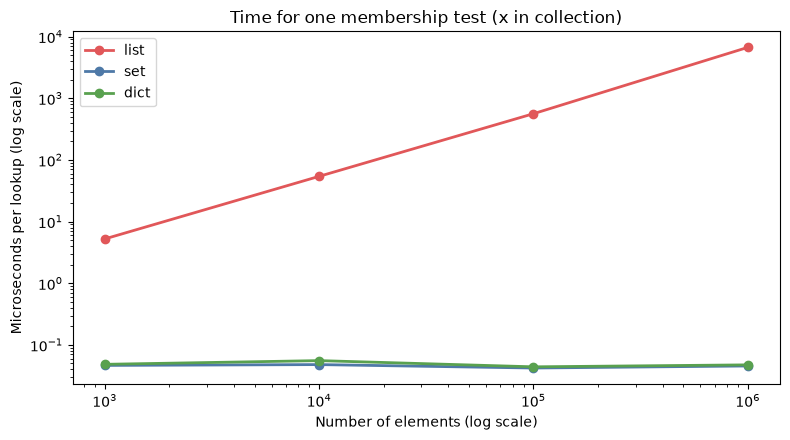

n =     1,000: list       5.24 µs | set 0.047 µs | list is 112x slower
n =    10,000: list      54.17 µs | set 0.048 µs | list is 1,128x slower
n =   100,000: list     561.93 µs | set 0.042 µs | list is 13,303x slower
n = 1,000,000: list    6686.88 µs | set 0.046 µs | list is 146,626x slower


In [5]:
import timeit

import matplotlib.pyplot as plt

sizes = [1_000, 10_000, 100_000, 1_000_000]
results = {"list": [], "set": [], "dict": []}
for n in sizes:
    data_list = list(range(n))
    data_set = set(data_list)
    data_dict = dict.fromkeys(data_list)
    target = n - 1                                   # worst case for the list: the last element
    for name, coll in (("list", data_list), ("set", data_set), ("dict", data_dict)):
        t = min(timeit.repeat(lambda: target in coll, number=200, repeat=3)) / 200
        results[name].append(t * 1e6)                # microseconds per lookup

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, color in (("list", "#E15759"), ("set", "#4E79A7"), ("dict", "#59A14F")):
    ax.plot(sizes, results[name], marker="o", lw=2, color=color, label=name)
ax.set(xscale="log", yscale="log", title="Time for one membership test (x in collection)",
       xlabel="Number of elements (log scale)", ylabel="Microseconds per lookup (log scale)")
ax.legend()
plt.tight_layout()
plt.show()

for i, n in enumerate(sizes):
    print(f"n = {n:>9,}: list {results['list'][i]:10.2f} µs | set {results['set'][i]:.3f} µs | "
          f"list is {results['list'][i] / results['set'][i]:,.0f}x slower")

The list time grows in proportion to $n$. The set and dict times stay almost flat. For one million elements, the list is many thousands of times slower (the last line of the output gives the exact factor on your machine).

*Insight: Use a `set` or `dict` when your code asks "is this value present?" many times. Use a `list` when order matters and you mostly read items in sequence.*

## Real-World Use Case or Analogy

- A **list** is a queue of people: the order matters, and to find one person you look at each face in turn.
- A **dict** is a phone book indexed by name: you go directly to the correct page.
- A **set** is a guest list at the door: the guard only needs to know if a name is on it.
- A **tuple** is a printed ticket: the seat number and the date do not change after printing.

A web service that checks API keys keeps the valid keys in a `set` (or a database index). With a list, every request would scan all keys, and the service would slow down as the number of customers grows.